# 07 – Change detection in the Ajoie (L10 project transfer) and draft figure

**Goal.** Turn the bi-temporal Sentinel-2 composites into a change map of forest canopy decline after the 2018 drought, and decide on a threshold in a documented way.

Plan following the L10 project-transfer template:

| Item | Decision |
|---|---|
| Change type and output | canopy decline, as **continuous** change (ΔNDVI, ΔNDMI, ΔNBR) and as a **categorical** map (stable / recovered after 2018 / decline 2019 only / persistent decline) |
| Dates and comparability | late-summer median composites (15 Aug – 30 Sep), same window in every year, same sensor, same 10 m grid; baseline 2017 (pre-drought), targets 2018, 2019, 2020 |
| Method | traditional image differencing of indices (no labels needed). Deep-learning change detectors from the lesson (ChangeStar) are trained on high-resolution building change and do not apply to 10 m forest condition |
| Threshold strategy | three options compared: fixed value, Otsu, robust z-score relative to all forest pixels; plus a persistence rule and a minimum mapping unit |
| Forest mask | ESA WorldCover 2021 tree cover, shrunk by one pixel. A first run without this step flagged thin lines along every forest edge and trees inside villages (mixed pixels, small shifts between years) |
| Validation | informal: agreement between NDVI- and NDMI-based flags, multi-year trajectories of the flagged pixels, visual check on SWISSIMAGE in a split map. No field reference is available |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path("..").resolve() / "scripts"))   # folder containing sds_utils.py

import numpy as np, pandas as pd, xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, ListedColormap
from matplotlib.patches import Patch
from skimage.filters import threshold_otsu
from skimage.morphology import remove_small_objects
from sklearn.metrics import cohen_kappa_score
import sds_utils as su
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

AOI, WIN, BASE = "ajoie_ju", "late", 2017
YEARS = [2017, 2018, 2019, 2020, 2022, 2024, 2025, 2026]
Z_THR, MMU_PIX = -1.5, 3            # robust z threshold; minimum mapping unit = 3 pixels (300 m2)

comp = {y: su.open_composite(AOI, y, WIN) for y in YEARS if su.composite_path(AOI, y, WIN).exists()}
anc = su.load_ancillary(AOI)
forest = anc["forest"].values == 1
tr_, W, H, xs, ys = su.aoi_grid(AOI)
EXT = [xs[0] / 1e3, xs[-1] / 1e3, ys[-1] / 1e3, ys[0] / 1e3]     # km, for imshow
print(sorted(comp), "|", f"interior forest: {forest.sum() / 1e4:.0f} km2 ({forest.mean():.0%} of the AOI); "
      f"all tree cover: {(anc['forest_all'].values == 1).sum() / 1e4:.0f} km2")

[2017, 2018, 2019, 2020, 2022, 2024, 2025, 2026] | interior forest: 67 km2 (38% of the AOI); all tree cover: 77 km2


## 1 · Are the dates comparable?
Image differencing only works if the two dates differ in the thing of interest and not in season, illumination or data quality. The table checks the number of valid observations behind each composite and the level of the forest median, which shifts from year to year with phenology and weather.

In [2]:
rows = []
for y, ds in comp.items():
    rows.append(dict(year=y, scenes=ds.attrs.get("n_scenes"), days=ds.attrs.get("n_days"),
                     median_valid_obs=float(np.median(ds["n_obs"].values[forest])),
                     share_lt3_obs=float((ds["n_obs"].values[forest] < 3).mean()),
                     NDVI_forest_median=float(np.nanmedian(ds["NDVI"].values[forest])),
                     NDMI_forest_median=float(np.nanmedian(ds["NDMI"].values[forest]))))
comparab = pd.DataFrame(rows).set_index("year").round(3)
comparab.to_csv(su.TABLES / "07_comparability.csv")
comparab

,scenes,days,median_valid_obs,share_lt3_obs,NDVI_forest_median,NDMI_forest_median
year,,,,,,
2017,11,6,5.0,0.004,0.864,0.351
2018,16,9,6.0,0.000,0.819,0.294
2019,15,8,6.0,0.000,0.867,0.326
2020,10,5,4.0,0.135,0.782,0.287
2022,24,6,4.0,0.091,0.877,0.329
2024,10,5,3.0,0.433,0.854,0.342
2025,23,12,7.0,0.000,0.870,0.359
2026,16,8,7.0,0.000,0.864,0.333


The forest median moves by a few hundredths of NDVI between years. A fixed threshold on ΔNDVI would turn that whole-scene shift into change. This is the reason for the relative (z-score) threshold below, which is centred on the median change of all forest pixels.

## 2 · Continuous change: index differences 2017 → 2019

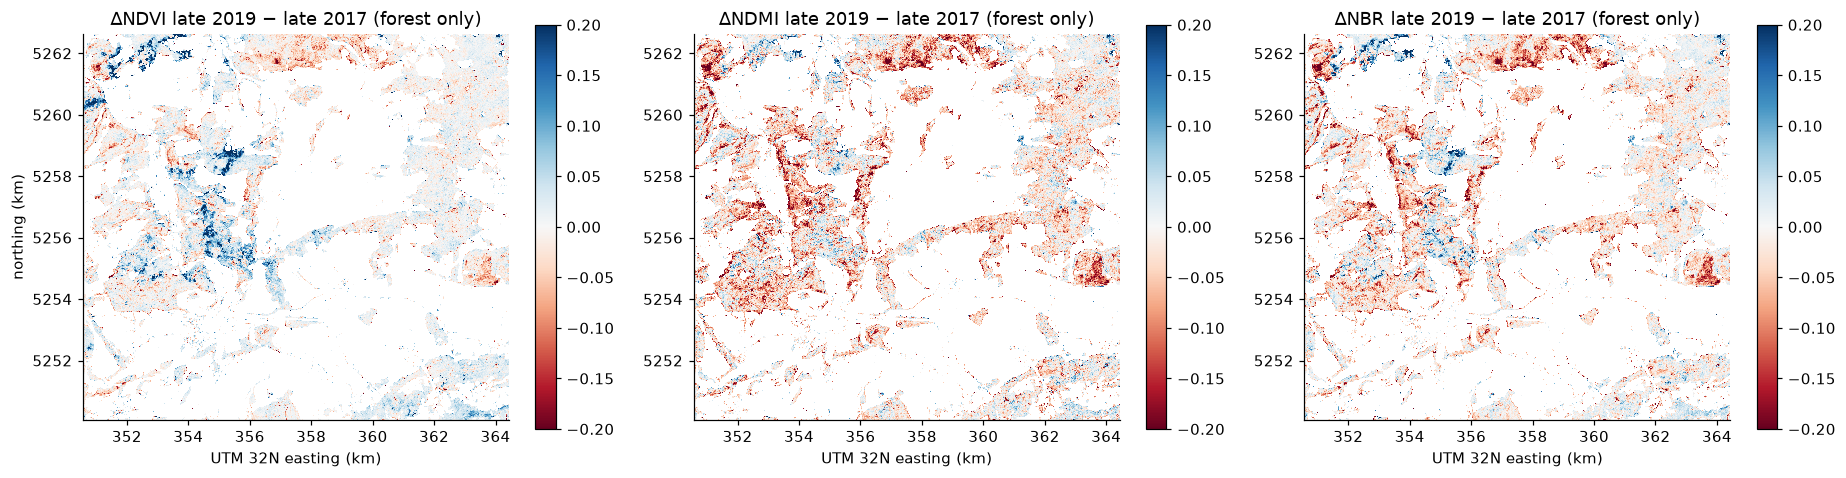

In [3]:
def delta(var, year):
    d = comp[year][var].values - comp[BASE][var].values
    ok = forest & (comp[year]["n_obs"].values >= 2) & (comp[BASE]["n_obs"].values >= 2)
    return np.where(ok, d, np.nan)

def robust_z(d):
    med = np.nanmedian(d); mad = np.nanmedian(np.abs(d - med))
    return (d - med) / (1.4826 * mad + 1e-9)

fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
for a, v in zip(ax, ("NDVI", "NDMI", "NBR")):
    im = a.imshow(delta(v, 2019), cmap="RdBu", norm=TwoSlopeNorm(0, -0.2, 0.2), extent=EXT, interpolation="nearest")
    a.set_title(f"Δ{v} late 2019 − late 2017 (forest only)"); a.set_xlabel("UTM 32N easting (km)")
    plt.colorbar(im, ax=a, shrink=0.75)
ax[0].set_ylabel("northing (km)")
plt.tight_layout(); plt.savefig(su.FIGS / "07_delta_indices_2019.png", dpi=150); plt.show()

## 3 · Threshold strategies
Three ways to turn ΔNDVI into a binary decline mask, compared on the flagged area. Otsu assumes a bimodal histogram, which a small damaged fraction does not produce, so it is expected to fail here.

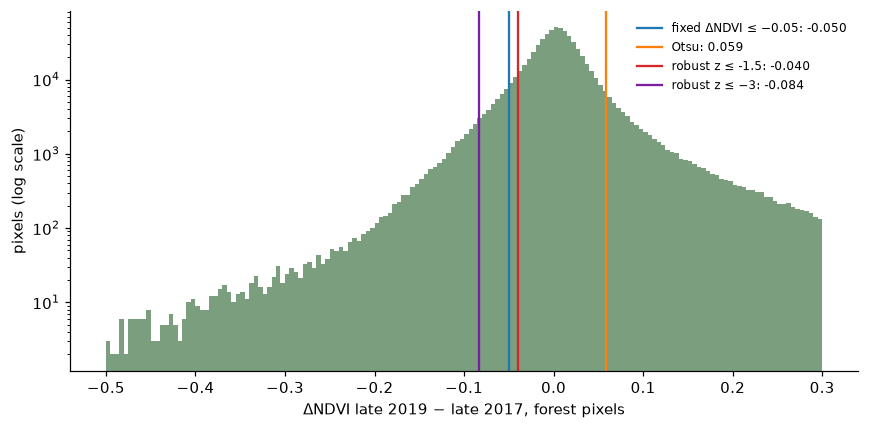

,strategy,dNDVI_threshold,flagged_share,flagged_km2
0,fixed ΔNDVI ≤ −0.05,-0.0500,0.0806,5.3907
1,Otsu,0.0588,0.9153,61.2385
2,robust z ≤ -1.5,-0.0399,0.1102,7.3708
3,robust z ≤ −3,-0.0835,0.0304,2.0320


In [4]:
d19 = delta("NDVI", 2019); v = d19[np.isfinite(d19)]
z19 = robust_z(d19)
thr = {"fixed ΔNDVI ≤ −0.05": -0.05,
       "Otsu": float(threshold_otsu(v)),
       f"robust z ≤ {Z_THR}": float(np.nanmedian(d19) + Z_THR * 1.4826 * np.nanmedian(np.abs(v - np.median(v)))),
       "robust z ≤ −3": float(np.nanmedian(d19) - 3 * 1.4826 * np.nanmedian(np.abs(v - np.median(v))))}
tbl = pd.DataFrame([dict(strategy=k, dNDVI_threshold=t, flagged_share=float((v <= t).mean()),
                         flagged_km2=float((v <= t).sum() / 1e4)) for k, t in thr.items()]).round(4)
tbl.to_csv(su.TABLES / "07_threshold_strategies.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(v, bins=np.linspace(-0.5, 0.3, 161), color="#7a9e7e")
for (k, t), c in zip(thr.items(), ("#1f77b4", "#ff7f0e", "#d62728", "#7b1fa2")):
    ax.axvline(t, color=c, lw=1.5, label=f"{k}: {t:.3f}")
ax.set_yscale("log"); ax.set_xlabel("ΔNDVI late 2019 − late 2017, forest pixels"); ax.set_ylabel("pixels (log scale)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(su.FIGS / "07_threshold_histogram.png", dpi=150); plt.show()
tbl

## 4 · Categorical change map: persistence and minimum mapping unit
A single-year drop can be late-summer leaf shedding that recovers the next spring (early senescence in 2018 was widespread and mostly reversible). Decline is therefore split by persistence, using the same relative threshold in every year. Patches below the minimum mapping unit are dropped, since isolated pixels are mostly noise at 10 m.

In [5]:
flag = {y: (robust_z(delta("NDVI", y)) <= Z_THR) for y in (2018, 2019, 2020) if y in comp}
valid = np.isfinite(d19)
cat = np.zeros(d19.shape, "uint8")                               # 0 = no data / non-forest
cat[valid] = 1                                                   # 1 = stable
cat[valid & flag[2018] & ~flag[2019]] = 2                        # 2 = 2018 only (recovered)
cat[valid & flag[2019] & ~flag.get(2020, flag[2019])] = 3        # 3 = decline 2019, not 2020
persistent = valid & flag[2019] & flag.get(2020, flag[2019])
persistent = remove_small_objects(persistent, min_size=MMU_PIX, connectivity=2)
cat[(cat == 1) & valid & flag[2019] & flag.get(2020, flag[2019])] = 3   # below MMU -> not counted as persistent
cat[persistent] = 4                                              # 4 = persistent decline (2019 and 2020)
CAT = {1: "stable", 2: "low NDVI in 2018, not in 2019", 3: "decline 2019, not persistent", 4: "persistent decline 2019–2020"}
CAT_COL = {1: "#cfe3cf", 2: "#f2c94c", 3: "#f2994a", 4: "#b22222"}
area = pd.Series({CAT[k]: (cat == k).sum() / 1e4 for k in CAT}, name="km2").to_frame()
area["share_of_forest_%"] = 100 * area["km2"] / area["km2"].sum()
area.round(2).to_csv(su.TABLES / "07_change_categories.csv")

# vector output: persistent-decline patches with area (L10: output format)
patches = su.labels_to_gdf(np.where(cat == 4, 1, 0), tr_).dissolve().explode(index_parts=False).reset_index(drop=True)
patches["area_m2"] = patches.area.round(0); patches["patch_id"] = np.arange(1, len(patches) + 1)
patches = patches[["patch_id", "area_m2", "geometry"]]
patches.to_file(su.PROC / f"{AOI}_persistent_decline.gpkg", driver="GPKG")
da = xr.DataArray(cat, coords=dict(y=ys, x=xs), dims=("y", "x")).rio.write_crs(su.CRS_UTM)
da.rio.to_raster(su.PROC / f"{AOI}_change_categories.tif", compress="deflate")
print(f"{len(patches)} persistent-decline patches, median {patches.area_m2.median():.0f} m2, largest {patches.area_m2.max() / 1e4:.1f} ha")
area.round(2)

1421 persistent-decline patches, median 500 m2, largest 3.4 ha


,km2,share_of_forest_%
stable,55.55,83.02
"low NDVI in 2018, not in 2019",3.99,5.96
"decline 2019, not persistent",6.02,9.00
persistent decline 2019–2020,1.35,2.01


## 5 · Informal validation
**(a) Do two indices agree?** NDVI (red/NIR) and NDMI (NIR/SWIR) use partly different bands. Agreement of the two decline flags is a consistency check, not an accuracy estimate.

In [6]:
f_ndvi = (z19 <= Z_THR)[valid]
f_ndmi = (robust_z(delta("NDMI", 2019)) <= Z_THR)[valid]
agree = pd.crosstab(pd.Series(f_ndvi, name="NDVI flag"), pd.Series(f_ndmi, name="NDMI flag"), normalize="all").round(4)
print(f"Cohen's kappa NDVI vs NDMI flag (2019): {cohen_kappa_score(f_ndvi, f_ndmi):.3f} | "
      f"share of NDVI-flagged pixels also flagged by NDMI: {(f_ndvi & f_ndmi).sum() / f_ndvi.sum():.1%}")
agree

Cohen's kappa NDVI vs NDMI flag (2019): 0.527 | share of NDVI-flagged pixels also flagged by NDMI: 58.7%


NDMI flag,False,True
NDVI flag,,
False,0.8415,0.0483
True,0.0455,0.0647


**(b) What happens to the flagged pixels afterwards?** If the persistent class is real canopy loss, its NDVI should stay below the stable class for years. If it is noise, it should return to the stable level immediately.

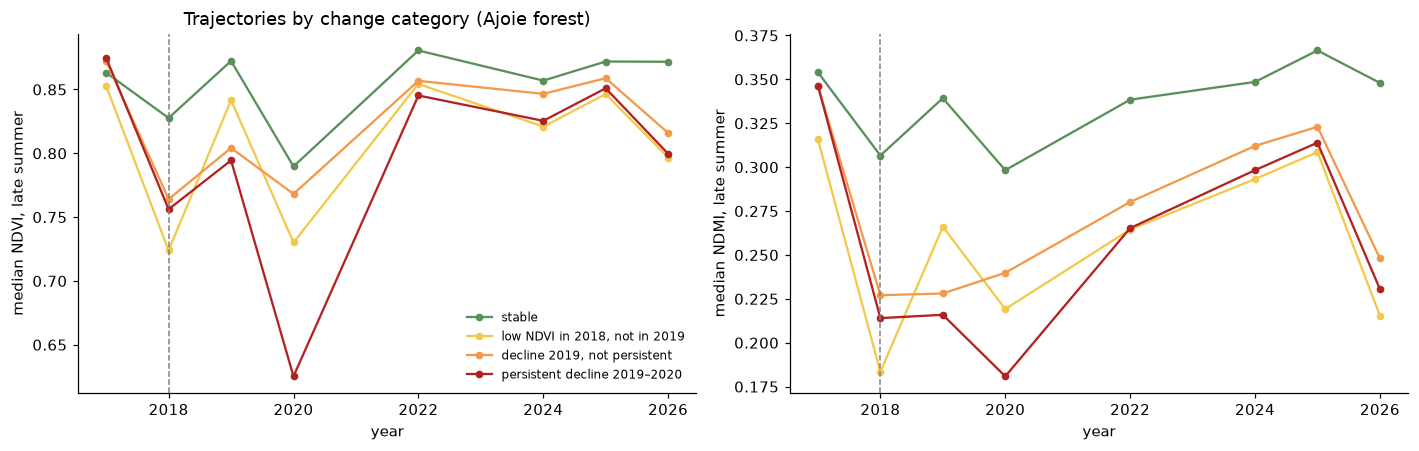

category,"decline 2019, not persistent","low NDVI in 2018, not in 2019",persistent decline 2019–2020,stable
year,,,,
2017,0.872,0.853,0.875,0.863
2018,0.764,0.724,0.756,0.828
2019,0.804,0.842,0.794,0.872
2020,0.768,0.730,0.625,0.790
2022,0.857,0.854,0.845,0.881
2024,0.847,0.821,0.825,0.857
2025,0.859,0.846,0.851,0.872
2026,0.816,0.797,0.800,0.872


In [7]:
rows = []
for y, ds in comp.items():
    for k, name in CAT.items():
        m = cat == k
        rows.append(dict(year=y, category=name, NDVI=float(np.nanmedian(ds["NDVI"].values[m])),
                         NDMI=float(np.nanmedian(ds["NDMI"].values[m]))))
traj = pd.DataFrame(rows)
traj.to_csv(su.TABLES / "07_trajectories_by_category.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, v in zip(ax, ("NDVI", "NDMI")):
    for k, name in CAT.items():
        t = traj[traj.category == name]
        a.plot(t.year, t[v], "-o", ms=4, color=CAT_COL[k] if k > 1 else "#5a8f5a", label=name)
    a.axvline(2018, color="grey", ls="--", lw=1); a.set_xlabel("year"); a.set_ylabel(f"median {v}, late summer")
ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("Trajectories by change category (Ajoie forest)")
plt.tight_layout(); plt.savefig(su.FIGS / "07_trajectories_by_category.png", dpi=150); plt.show()
traj.pivot(index="year", columns="category", values="NDVI").round(3)

**(c) Visual check.** Split map: SWISSIMAGE (current orthophoto) on the left, change categories on the right. Saved as HTML; open it and look at a few red patches. Clear-cuts and forest roads show up as persistent decline as well, which is the main known confusion.


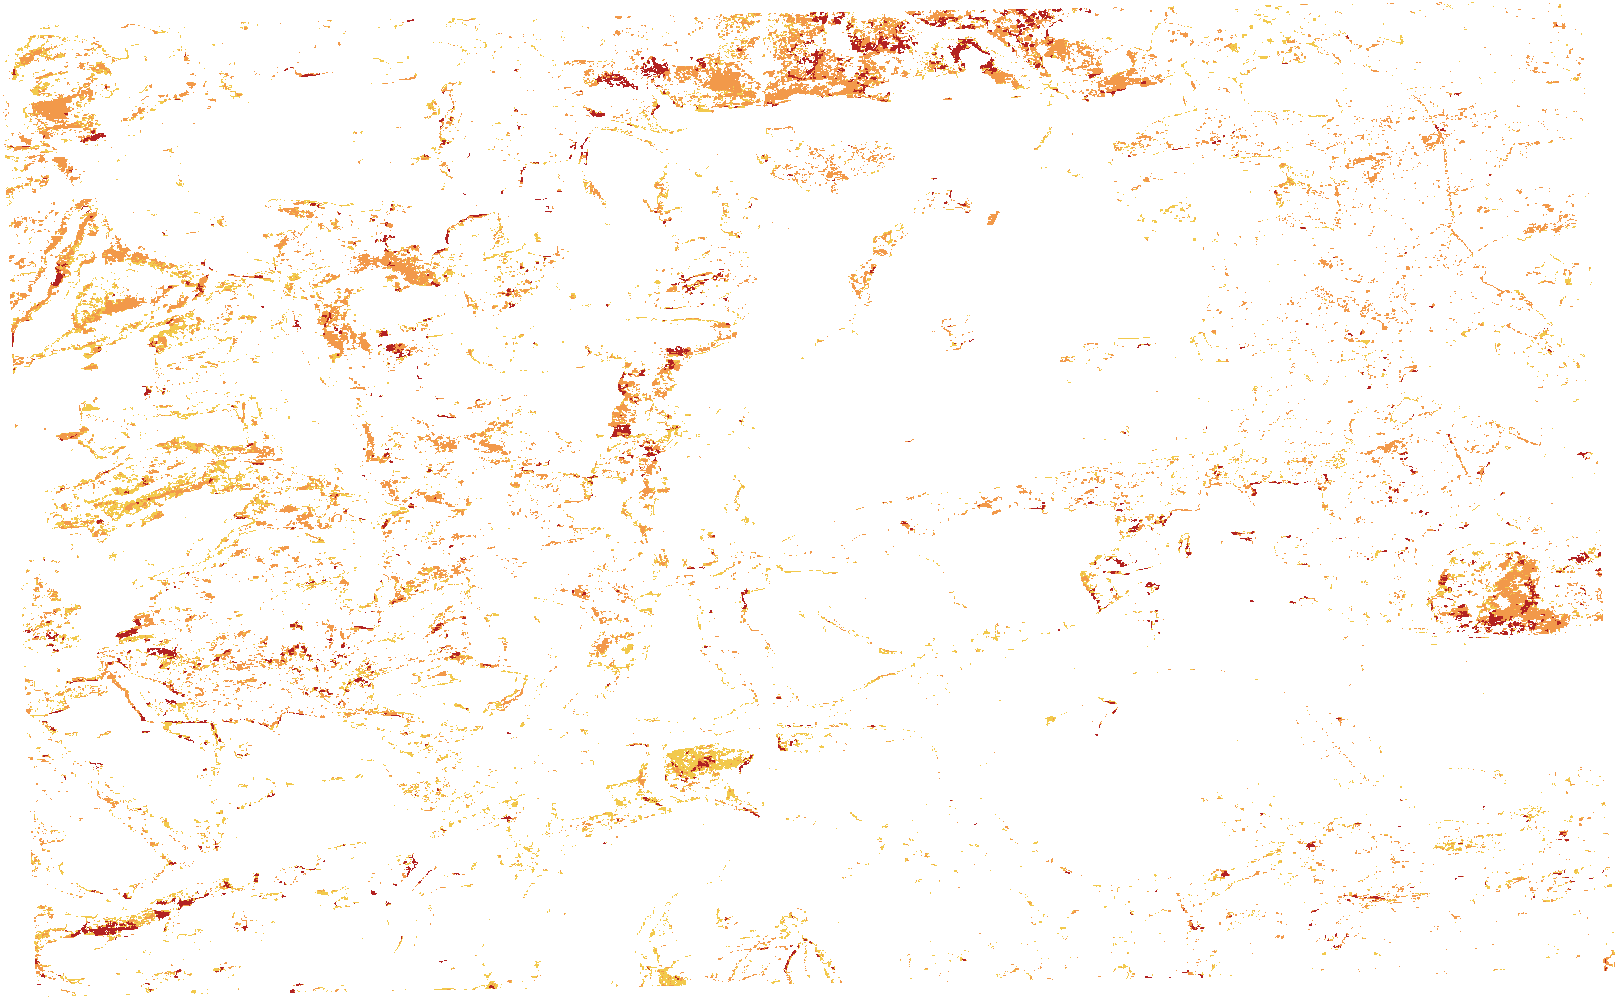

In [8]:
import folium
from folium.plugins import DualMap
rgba = np.zeros(cat.shape + (4,), "uint8")
for k, c in CAT_COL.items():
    if k == 1: continue
    rgba[cat == k] = [int(c[i:i + 2], 16) for i in (1, 3, 5)] + [255]
da_show = xr.DataArray(np.where(cat > 1, cat, np.nan).astype("float32"), coords=dict(y=ys, x=xs), dims=("y", "x"))
img, bnds = su.overlay_png(da_show, ListedColormap([CAT_COL[2], CAT_COL[3], CAT_COL[4]]), 1.5, 4.5)
x0, y0, x1, y1 = su.AOIS[AOI]["bbox"]
m = DualMap(location=[(y0 + y1) / 2, (x0 + x1) / 2], zoom_start=12, tiles=None)
SWISSIMG = "https://wmts.geo.admin.ch/1.0.0/ch.swisstopo.swissimage/default/current/3857/{z}/{x}/{y}.jpeg"
folium.TileLayer(tiles=SWISSIMG, attr="© swisstopo", name="SWISSIMAGE").add_to(m.m1)
folium.TileLayer(tiles=SWISSIMG.replace("swissimage", "pixelkarte-grau"), attr="© swisstopo", name="swisstopo grey map").add_to(m.m2)
folium.raster_layers.ImageOverlay(img, bnds, opacity=0.9, name="change categories").add_to(m.m2)
m.save(su.FIGS / "07_splitmap_change_ajoie.html")
m

## 6 · Draft figure (week 9 milestone)

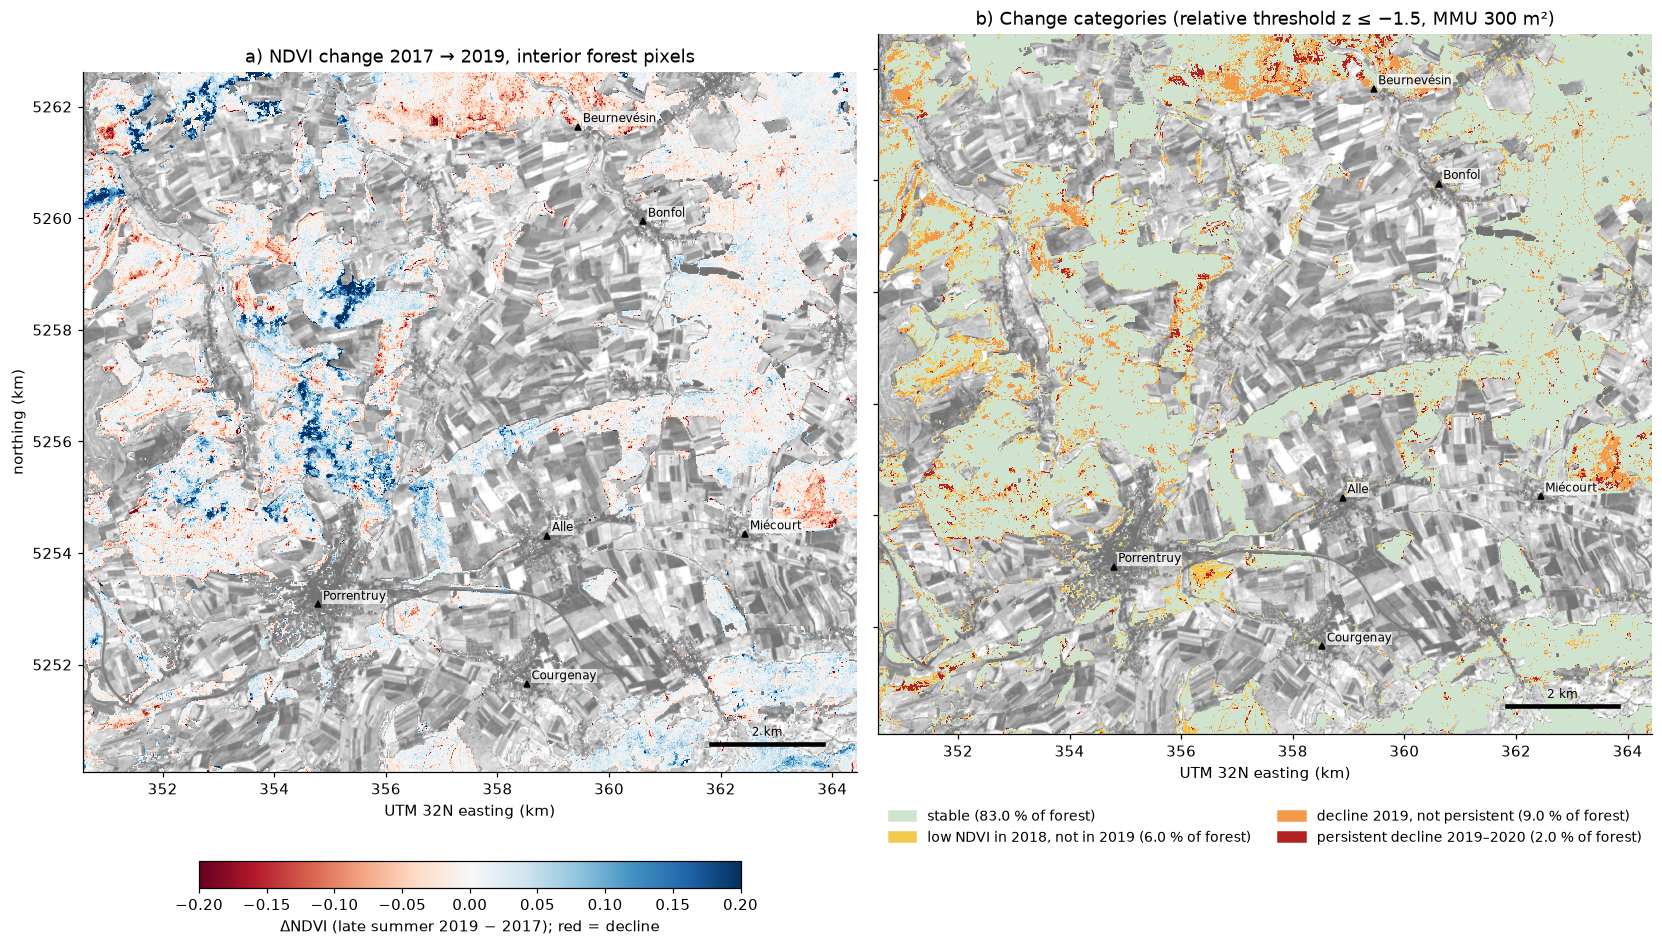

In [9]:
PLACES = {"Porrentruy": (7.075, 47.415), "Alle": (7.129, 47.427), "Miécourt": (7.176, 47.428),
          "Beurnevésin": (7.134, 47.493), "Courgenay": (7.125, 47.403), "Bonfol": (7.150, 47.478)}   # approximate, orientation only
pl = gpd.GeoSeries(gpd.points_from_xy(*zip(*PLACES.values())), crs=4326).to_crs(su.CRS_UTM)
bg = su.stretch(comp[BASE]["B08"].values)

fig, ax = plt.subplots(1, 2, figsize=(15, 8.6), sharey=True, layout="constrained")
ax[0].imshow(bg, cmap="gray", extent=EXT, alpha=0.55)
im = ax[0].imshow(d19, cmap="RdBu", norm=TwoSlopeNorm(0, -0.2, 0.2), extent=EXT, interpolation="nearest")
cb = fig.colorbar(im, ax=ax[0], location="bottom", shrink=0.7, pad=0.02); cb.set_label("ΔNDVI (late summer 2019 − 2017); red = decline")
ax[0].set_title("a) NDVI change 2017 → 2019, interior forest pixels")
ax[1].imshow(bg, cmap="gray", extent=EXT, alpha=0.55)
show = np.where(cat > 0, cat, np.nan)
ax[1].imshow(show, cmap=ListedColormap([CAT_COL[k] for k in CAT]), vmin=0.5, vmax=4.5, extent=EXT, interpolation="nearest")
ax[1].legend(handles=[Patch(color=CAT_COL[k], label=f"{v} ({area.loc[v, 'share_of_forest_%']:.1f} % of forest)") for k, v in CAT.items()],
             loc="upper center", bbox_to_anchor=(0.5, -0.09), ncols=2, fontsize=9, frameon=False)
ax[1].set_title("b) Change categories (relative threshold z ≤ −1.5, MMU 300 m²)")
for a in ax:
    for name, p in zip(PLACES, pl):
        a.plot(p.x / 1e3, p.y / 1e3, "k^", ms=4); a.annotate(name, (p.x / 1e3, p.y / 1e3), xytext=(3, 3), textcoords="offset points", fontsize=8,
                                                                 bbox=dict(fc="white", ec="none", alpha=0.7, pad=0.5))
    a.set_xlabel("UTM 32N easting (km)"); a.set_aspect("equal")
    a.plot([EXT[1] - 2.6, EXT[1] - 0.6], [EXT[2] + 0.5] * 2, "k-", lw=3); a.text(EXT[1] - 1.6, EXT[2] + 0.65, "2 km", ha="center", fontsize=8)
ax[0].set_ylabel("northing (km)")
plt.savefig(su.FIGS / "fig1_ajoie_change_2017_2019.png", dpi=200, bbox_inches="tight"); plt.show()

**Figure 1.** Change in late-summer NDVI between 2017 and 2019 (a) and derived change categories (b) for forest pixels in the Ajoie (Canton of Jura), based on Sentinel-2 L2A median composites (15 Aug – 30 Sep, 10 m, EPSG:32632) and the ESA WorldCover 2021 tree-cover mask (interior pixels only, edges removed); background: near-infrared band 2017. About 83 % of the interior forest shows no relative decline, 9 % dropped in 2019 only, and 2 % (1.35 km², about 1,400 patches with a median size of 500 m²) stayed low in 2020; the largest clusters lie north-west of Beurnevésin and east of Miécourt, the two areas where the STDL HETRES project surveyed beech damage. The map shows spectral decline of 10 m pixels, which also includes harvesting and other disturbances, and has not been validated against field data.

## What the run shows
- **Comparability.** The forest median NDVI moves between 0.78 (2020) and 0.88 (2022) from year to year. 2020 and 2024 rest on few observations (5 days; 14 % and 43 % of forest pixels with fewer than three valid observations), so composites of these years are noisier.
- **Thresholds.** The fixed threshold flags 8.1 % of the forest, the relative threshold (z ≤ −1.5, equal to ΔNDVI ≤ −0.040 here) 11.0 %, the strict one (z ≤ −3) 3.0 %. Otsu puts its threshold at +0.06 and flags 92 %, so it is unusable for a rare change class.
- **Persistence.** Only 2.0 % of the interior forest is low in both 2019 and 2020. A further 9.0 % is low in 2019 only and 6.0 % was low in 2018 but not in 2019, which matches the reports of early leaf fall in 2018 that was followed by normal leaf-out in most stands.
- **Trajectories.** Persistent-decline pixels started at the same NDVI as stable forest in 2017 (0.875 vs 0.863), fell to 0.625 in 2020 and came back to 0.845 by 2022, staying 0.02–0.07 below stable forest until 2026. The signal at 10 m therefore recovers within two to three years, most likely through understory and neighbouring crowns filling the gaps. Dead crowns themselves cannot be followed at this resolution.
- **Agreement of indices.** NDVI and NDMI flags agree moderately (Cohen's kappa 0.53; 59 % of NDVI-flagged pixels are also flagged by NDMI).
- **Edges.** Without the one-pixel erosion of the forest mask, thin lines along forest edges and trees in villages were flagged. The interior mask removed them (persistent decline 2.3 % → 2.0 %).

## Notes
- **Threshold choice.** The relative threshold (robust z ≤ −1.5 of all forest pixels) is used for the map because it is insensitive to the year-to-year shift of the forest median (section 1). The fixed threshold is easier to explain but moves with that shift; Otsu is not suited to a small damaged fraction.
- **What this map can and cannot say.** It shows where the canopy signal dropped and stayed low. It cannot say that beech died, or that drought was the cause.
- **Not used:** ChangeStar (`geoai.change_detection`) from the lesson. It detects building change on high-resolution imagery and has no forest-condition classes.
- **Next:** notebook 08 compares these index-based changes with change in foundation-model embeddings (TESSERA) and predicts the continuous 2019 change with regression models.